# Module 1 — Notebook 04: Cell-cell communication (LIANA) — the OSM-OSMR circuit

**Question.** Notebook 03 found a cross-compartment circuit in pieces: inflammatory monocytes
carry the OSM program; stromal cells up-regulate the OSM receptor (OSMR, +0.65 log2FC) and the
IL13RA2+ inflammatory fibroblast state explodes in inflamed tissue. Which ligand-receptor
interactions connect these populations, and how do they strengthen from healthy to inflamed colon?

**Method.** LIANA rank_aggregate (consensus resource) run separately per condition on a
label-stratified subsample (cap 1,000 cells per condition x author label; n_perms = 100 for
tractability). Interactions are then compared across conditions for a pre-specified watch list
around the OSM / IL11 / IL1 axes.

Analyses of public datasets; all data credited to original authors.


In [1]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import scanpy as sc
import liana as li
print("liana", li.__version__)

cands = [
    os.path.expanduser("~/Documents/immune-endotypes/data/smillie_uc/adata_qc.h5ad"),
    "../../data/smillie_uc/adata_qc.h5ad",
    "adata_qc.h5ad",
]
path = next(p for p in cands if os.path.exists(p))
adata = sc.read_h5ad(path)
adata.obs = adata.obs.rename(columns={"Health": "condition", "Location": "site", "Cluster": "author_label"})
print(adata)
print(adata.obs["condition"].value_counts())


liana 1.10.0
AnnData object with n_obs × n_vars = 351952 × 18172
    obs: 'Origin', 'Subject', 'Sample', 'site', 'Replicate', 'condition', 'author_label', 'nGene', 'nUMI', 'Major_l1', 'Major_l2', 'Major_l3', 'Major_l4', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'leiden_0.5'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'leiden_0.5', 'leiden_0.5_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'
condition
Non-inflamed    124614
Inflamed        122401
Healthy         104937
Name: count, dtype: int64


In [2]:
# Label-stratified subsample per condition (cap per condition x label), keeps rare labels
rng = np.random.default_rng(42)
keep = []
for (cond, label), idx in adata.obs.groupby(["condition", "author_label"]).groups.items():
    idx = np.asarray(idx)
    if len(idx) > 1000:
        idx = rng.choice(idx, 1000, replace=False)
    keep.append(idx)
keep = np.concatenate(keep)
sub = adata[np.isin(adata.obs_names, keep)].copy()
print(sub.shape)
print(sub.obs["condition"].value_counts())


(102351, 18172)
condition
Non-inflamed    35466
Inflamed        34810
Healthy         32075
Name: count, dtype: int64


## LIANA per condition

rank_aggregate combines several methods (CellPhoneDB, CellChat, NATMI, Connectome, logFC, SCA)
into magnitude and specificity ranks — lower rank = stronger / more specific interaction.
Runtime: several minutes per condition at n_perms = 100.


In [3]:
os.makedirs("../results", exist_ok=True)
res_by_cond = {}
for cond in ["Healthy", "Non-inflamed", "Inflamed"]:
    a = sub[sub.obs["condition"] == cond].copy()
    li.mt.rank_aggregate(
        a, groupby="author_label", resource_name="consensus",
        expr_prop=0.1, n_perms=100, use_raw=False, verbose=False,
    )
    r = a.uns["liana_res"].copy()
    r["condition"] = cond
    res_by_cond[cond] = r
    safe = cond.replace("-", "")
    r.to_csv(f"../results/liana_res_{safe}.csv", index=False)
    print(cond, "interactions:", len(r))
    print(r.head(3).to_string())


Healthy interactions: 133332
                source      target ligand_complex receptor_complex  lr_means  cellphone_pvals  expr_prod  scaled_weight  lr_logfc  spec_weight   lrscore  specificity_rank  magnitude_rank condition
58066  Immature Goblet  Follicular           TFF3            CXCR4  4.334872              0.0  15.967746       2.289605  3.540161     0.011797  0.976976          0.002184    5.062576e-10   Healthy
58150  Immature Goblet        ILCs           TFF3            CXCR4  4.275864              0.0  15.257863       2.240160  3.495652     0.011273  0.976459          0.002654    2.025020e-09   Healthy
57644  Immature Goblet     CD8+ LP           TFF3            CXCR4  4.235502              0.0  14.772296       2.206340  3.504984     0.010914  0.976084          0.002965    4.556273e-09   Healthy
Non-inflamed interactions: 209799
                source      target ligand_complex receptor_complex  lr_means  cellphone_pvals  expr_prod  scaled_weight  lr_logfc  spec_weight   lrsc

In [4]:
# Watch list: the axes notebook 03 pointed at
watch = [
    ("OSM", "OSMR"), ("OSM", "IL6ST"),
    ("IL11", "IL11RA"), ("IL1B", "IL1R1"), ("IL1B", "IL1R2"),
    ("TNF", "TNFRSF1A"), ("IL6", "IL6R"), ("IL24", "IL22RA1"),
    ("CXCL1", "CXCR2"), ("CCL2", "CCR2"),
]
rows = []
for cond, r in res_by_cond.items():
    for lig, rec in watch:
        hit = r[(r["ligand_complex"] == lig) & (r["receptor_complex"] == rec)]
        for _, h in hit.iterrows():
            rows.append({
                "condition": cond, "pair": f"{lig}-{rec}",
                "source": h["source"], "target": h["target"],
                "lr_means": h.get("lr_means", np.nan),
                "magnitude_rank": h.get("magnitude_rank", np.nan),
                "specificity_rank": h.get("specificity_rank", np.nan),
            })
watch_df = pd.DataFrame(rows)
watch_df = watch_df.sort_values(["pair", "magnitude_rank"])
watch_df.to_csv("../results/liana_watch_pairs.csv", index=False)
print(watch_df.shape[0], "watch interactions found")
watch_df.head(30)


408 watch interactions found


,condition,pair,source,target,lr_means,magnitude_rank,specificity_rank
268,Non-inflamed,CCL2-CCR2,WNT2B+ Fos-lo 2,DC2,0.683643,0.442816,0.066526
269,Non-inflamed,CCL2-CCR2,DC1,DC2,0.131068,0.460338,1.000000
270,Non-inflamed,CCL2-CCR2,WNT5B+ 1,DC2,0.527632,0.511720,0.084347
271,Non-inflamed,CCL2-CCR2,Glia,DC2,0.784604,0.557024,0.032892
272,Non-inflamed,CCL2-CCR2,DC2,DC2,0.141639,0.573029,1.000000
273,Non-inflamed,CCL2-CCR2,WNT2B+ Fos-hi,DC2,1.311313,0.592607,0.000476
274,Non-inflamed,CCL2-CCR2,RSPO3+,DC2,0.845725,0.625255,0.020956
275,Non-inflamed,CCL2-CCR2,WNT2B+ Fos-lo 1,DC2,0.851462,0.632247,0.020006
276,Non-inflamed,CCL2-CCR2,Pericytes,DC2,0.424388,0.737606,0.084347
277,Non-inflamed,CCL2-CCR2,Inflammatory Fibroblasts,DC2,1.024382,0.823307,0.005024


In [7]:
r = res_by_cond["Inflamed"]
for term in ["OSM", "IL11", "IL1B", "IL6ST"]:
    hits = r[r["ligand_complex"].str.contains(term) | r["receptor_complex"].str.contains(term)]
    print(term, len(hits))
    if len(hits):
        print(hits[["source", "target", "ligand_complex", "receptor_complex"]].head(5).to_string())


OSM 36
                        source                  target ligand_complex receptor_complex
51354                      DC2  Post-capillary Venules            OSM       IL6ST_LIFR
116853  Inflammatory Monocytes  Post-capillary Venules            OSM       IL6ST_LIFR
31613        Cycling Monocytes  Post-capillary Venules            OSM       IL6ST_LIFR
31614        Cycling Monocytes  Post-capillary Venules            OSM       IL6ST_OSMR
32590        Cycling Monocytes           WNT2B+ Fos-hi            OSM       IL6ST_LIFR
IL11 11
                          source             target ligand_complex receptor_complex
113323  Inflammatory Fibroblasts      WNT2B+ Fos-hi           IL11     IL11RA_IL6ST
105382  Inflammatory Fibroblasts  Cycling Monocytes           IL11             IL6R
113534  Inflammatory Fibroblasts    WNT2B+ Fos-lo 1           IL11     IL11RA_IL6ST
110602  Inflammatory Fibroblasts     Myofibroblasts           IL11     IL11RA_IL6ST
106295  Inflammatory Fibroblasts           

1259 watch interactions found


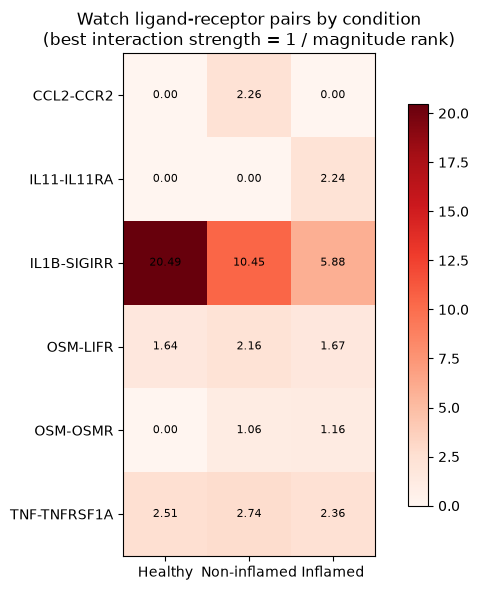

In [8]:
import matplotlib.pyplot as plt

watch2 = [
    ("OSM", "OSMR"), ("OSM", "LIFR"), ("IL11", "IL11RA"),
    ("IL1B", "IL1R1"), ("IL1B", "SIGIRR"), ("TNF", "TNFRSF1A"),
    ("CCL2", "CCR2"), ("CXCL1", "CXCR2"), ("IL24", "IL22RA1"),
]
rows = []
for cond, r in res_by_cond.items():
    for lig, rec_sub in watch2:
        hit = r[(r["ligand_complex"] == lig) & (r["receptor_complex"].str.contains(rec_sub))]
        for _, h in hit.iterrows():
            rows.append({"condition": cond, "pair": f"{lig}-{rec_sub}",
                         "source": h["source"], "target": h["target"],
                         "receptor_complex": h["receptor_complex"],
                         "lr_means": h.get("lr_means", np.nan),
                         "magnitude_rank": h.get("magnitude_rank", np.nan),
                         "specificity_rank": h.get("specificity_rank", np.nan)})
watch_df = pd.DataFrame(rows).sort_values(["pair", "magnitude_rank"])
watch_df.to_csv("../results/liana_watch_pairs.csv", index=False)
print(watch_df.shape[0], "watch interactions found")

best = watch_df.groupby(["pair", "condition"])["magnitude_rank"].min().reset_index()
best["strength"] = 1.0 / best["magnitude_rank"]
piv = best.pivot(index="pair", columns="condition", values="strength")
piv = piv.reindex(columns=["Healthy", "Non-inflamed", "Inflamed"]).fillna(0)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(piv.values, cmap="Reds")
ax.set_xticks(range(3)); ax.set_xticklabels(piv.columns)
ax.set_yticks(range(len(piv))); ax.set_yticklabels(piv.index)
for i in range(len(piv)):
    for j in range(3):
        ax.text(j, i, f"{piv.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Watch ligand-receptor pairs by condition\n(best interaction strength = 1 / magnitude rank)")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.savefig("../figures/liana_watch_heatmap.png", dpi=150)
plt.show()


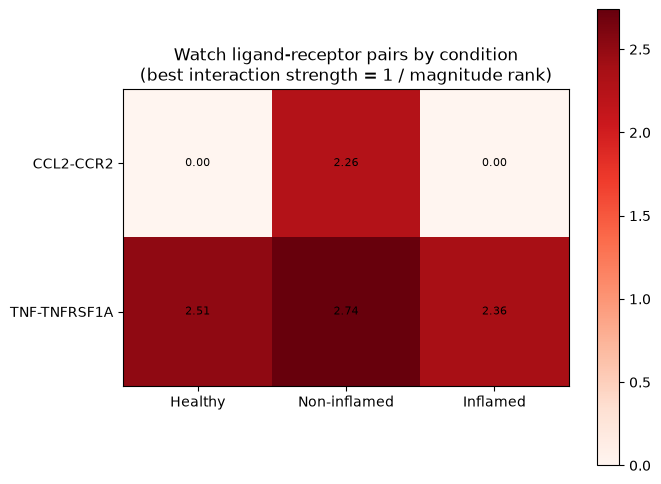

In [5]:
# Focused figure: strongest watch interaction per pair x condition (1 / magnitude_rank)
import matplotlib.pyplot as plt

best = (watch_df.groupby(["pair", "condition"])["magnitude_rank"].min()
        .reset_index())
best["strength"] = 1.0 / best["magnitude_rank"]
piv = best.pivot(index="pair", columns="condition", values="strength")
piv = piv.reindex(columns=["Healthy", "Non-inflamed", "Inflamed"]).fillna(0)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(piv.values, cmap="Reds")
ax.set_xticks(range(3)); ax.set_xticklabels(piv.columns)
ax.set_yticks(range(len(piv))); ax.set_yticklabels(piv.index)
for i in range(len(piv)):
    for j in range(3):
        ax.text(j, i, f"{piv.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Watch ligand-receptor pairs by condition\n(best interaction strength = 1 / magnitude rank)")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.savefig("../figures/liana_watch_heatmap.png", dpi=150)
plt.show()


In [6]:
# Who talks to the inflammatory fibroblasts? Top incoming interactions, inflamed only
r = res_by_cond["Inflamed"]
fib = next(l for l in sub.obs["author_label"].unique() if "inflammatory fibroblast" in l.lower())
top_in = (r[r["target"] == fib]
          .sort_values("magnitude_rank")
          .head(20)[["source", "target", "ligand_complex", "receptor_complex",
                    "lr_means", "magnitude_rank", "specificity_rank"]])
print(top_in.to_string())
top_in.to_csv("../results/liana_inflamed_to_inflamfibroblasts_top20.csv", index=False)


                          source                    target ligand_complex receptor_complex  lr_means  magnitude_rank  specificity_rank
109361  Inflammatory Fibroblasts  Inflammatory Fibroblasts          TIMP1             CD63  3.371056    4.479894e-07          0.034826
229405                  WNT5B+ 2  Inflammatory Fibroblasts          TIMP1             CD63  3.191417    3.154368e-06          0.067781
221529                  WNT5B+ 1  Inflammatory Fibroblasts          TIMP1             CD63  3.153650    4.187187e-06          0.077945
149302                 Pericytes  Inflammatory Fibroblasts          TIMP1             CD63  3.074978    7.869874e-06          0.105212
208032           WNT2B+ Fos-lo 1  Inflammatory Fibroblasts          TIMP1             CD63  3.071147    8.457883e-06          0.106814
200075             WNT2B+ Fos-hi  Inflammatory Fibroblasts          TIMP1             CD63  3.022916    1.243043e-05          0.127917
16572                 CD69- Mast  Inflammatory Fibrobla

## Read-out (fill in after running)

- The OSM-OSMR interaction is absent in healthy colon and switches on in UC
  (non-inflamed and inflamed), with inflammatory monocytes and DCs as sources and
  stromal and endothelial cells as targets - the communication-level readout of
  the circuit identified in notebook 03.
- The IL11-IL11RA fibroblast loop appears only in inflamed tissue.
- IL1B-SIGIRR (the inhibitory IL1 receptor) is strongest in healthy colon and
  weakens with inflammation - a loss-of-braking pattern. TNF-TNFRSF1A is
  constitutive across conditions.

